In [2]:
# Import packages

import os
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt

import rioxarray as rioxar
import xarray as xr 


## Fire Perimeter Data Exploration

Explore the fire perimeter data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include, at least, the CRS of the data and whether this is projected or geographic.

In [16]:
# Import fire perimeter shapefiles
eaton = gpd.read_file(os.path.join('data', 
                                    'Eaton_Perimeter_20250121.shp'))
palisades = gpd.read_file(os.path.join('data', 
                                    'Palisades_Perimieter_20250121.shp'))

# Import LA County perimeter
la_county = gpd.read_file(os.path.join('data','tl_2026_06037_edges.shp'))

<Axes: >

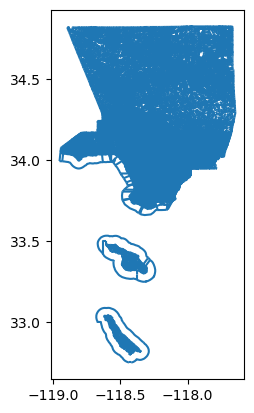

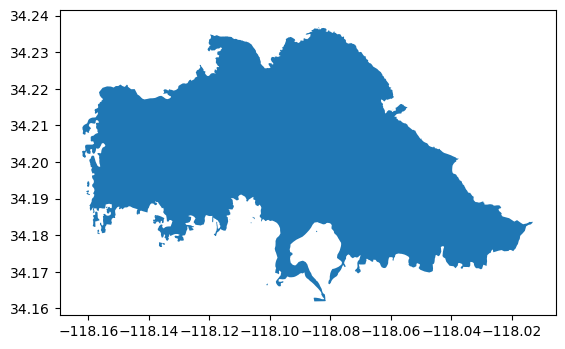

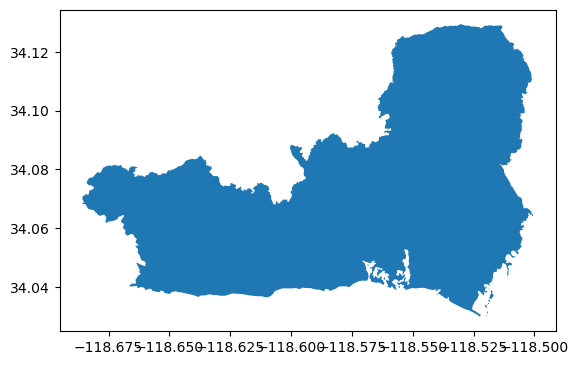

In [17]:
# View fire perimeters

la_county.plot()
eaton.plot()
palisades.plot()

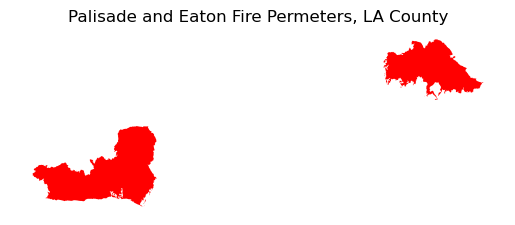

In [33]:
fig, ax = plt.subplots()

ax.axis('off')

#la_county.plot(ax = ax, 
#               color = 'lightblue',
#               alpha = 0.2)

eaton.plot(ax = ax, color = 'red')
palisades.plot(ax = ax, color= 'red')



ax.set_title("Palisade and Eaton Fire Permeters, LA County")
plt.show()

In [18]:
la_county.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [10]:
eaton.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

Eaton and Palisade Fire Perimeters were obtained from [CAL FIRE's Historical Fire Perimeter Dataset](https://www.arcgis.com/home/item.html?id=c3c10388e3b24cec8a954ba10458039d#overview) through the [County of Los Angeles](https://data.lacounty.gov/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about).  The county dissolved daily fire perimeters from the original dataset into a single burn perimeter.

Both shapefiles share the same CRS: EPSG: 4269.  It is a geographic (not projected) CRS. 

## NETCDF data import and exploration

Import the Landsat data using xr.open_dataset().

Explore the data and write a brief summary of the information you obtained from the preliminary exploration. Your summary should include a description of the data’s variables, dimensions, and coordinates.

In [55]:
# Import the landsat data
burnscar =xr.open_dataset("data\landsat8-2025-02-23-palisades-eaton.nc")
burnscar

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B ...
Data variables:
    red          (y, x) float32 16MB ...
    green        (y, x) float32 16MB ...
    blue         (y, x) float32 16MB ...
    nir08        (y, x) float32 16MB ...
    swir22       (y, x) float32 16MB ...
    spatial_ref  int64 8B ...

The landsat data contains 5 wavelength ranges as variables (`red`, `green`, `blue`, `nir08` (near infrared), and `swir22` (shortwave infrared)) in 3 dimensions (x,y, and band). Geospatial information is stored in the variable `spatial_ref`. There is only one band. Values are stored as floats.  The raster is 2742 cells wide and 1418 cells long, at a resolution of 30 meters.  It lies in the bounding box `(334395.0, 3756525.0, 416655.0, 3799065.0)`.  Reflectance values for each band are stored as unsigned integers (uint8).  The CRS of the coordinates is EPSG: 32611, which is a projected CRS.

## Restoring geospatial information
Use rio.crs to print the CRS of this dataset. Is this a geospatial object?

You may have noticed in section 3 that the geospatial information for this dataset is stored in the variable spatial_ref. Print the CRS by accessing the spatial_ref.crs_wkt attribute of the dataset.

Recover the geospatial information by using rio.write_crs() and the spatial reference information from part b.

Print the CRS of the updated dataset.

In [ ]:
# Identify CRS
print('CRS: ', burnscar.rio.crs)

CRS:  None


In [63]:
# Identify CRS through `spatial-ref`
print('CRS: ', burnscar.spatial_ref.crs_wkt)

CRS:  PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]


`rio.crs` does not return a CRS, indicating that this is not a geospatial object.  CRS information is stored under `spatial_ref`

In [64]:
# Restore geospatial infomration
burnscar = burnscar.rio.write_crs(burnscar.spatial_ref.crs_wkt, inplace = True)

# Confirm restoration
print('CRS :', burnscar.rio.crs)

CRS : EPSG:32611


## True Color Image
Without creating any new variables:
select the red, green, and blue variables (in that order) of the xarray.Dataset holding the Landsat data,
convert it to an xarray.DataArray using the to_dataarray() method, and then
use .plot.imshow() to create an RGB image with the data. There will be a warning; that’s ok.
Adjust the scale used for plotting the bands to get a true color image. HINT: Check the robust parameter.
To resolve the other warning, identify which bands have nan values. HINT: There are many ways of doing so. One option is to use numpy.isnan().

Use the .fillna() method for xarray.Datasets to replace any nan values in the Landsat data with zero.

Create a new true color image that gets plotted without warnings.

In a markdown cell write a brief explanation comparing the outputs for parts (a) and (e).

## False color image

Without creating any new variables, create a false color image by plotting the shortwave infrared (swir22), near-infrared, and red variables (in that order).

In [ ]:
=

## Map

Create a map showing the shortwave infrared/near-infrared/red false color image together with both fire perimeters. Customize it appropriately including, at least, an informative title and legend. You may also want to include text on the map to identify which fire is which.

Write a figure description for the map including a brief explanation of how false color imagery is being used.